In [2]:
import pandas as pd
import numpy as np

url = "https://raw.githubusercontent.com/jbrownlee/Datasets/master/pima-indians-diabetes.data.csv"
cols = ["Pregnancies","Glucose","BloodPressure","SkinThickness",
        "Insulin","BMI","DiabetesPedigreeFunction","Age","Outcome"]
df = pd.read_csv(url, names=cols)

print("=== SHAPE ===")
print(df.shape)

print("\n=== DTYPES ===")
print(df.dtypes)

print("\n=== HEAD ===")
print(df.head())

print("\n=== TARGET DISTRIBUTION ===")
print(df["Outcome"].value_counts())
print(df["Outcome"].value_counts(normalize=True).round(3))

print("\n=== ZERO COUNTS PER FEATURE ===")
zero_counts = (df[cols[:-1]] == 0).sum()
zero_pct = ((df[cols[:-1]] == 0).mean() * 100).round(1)
print(pd.DataFrame({"zeros": zero_counts, "pct": zero_pct}))

print("\n=== DESCRIBE ===")
print(df.describe().round(2))

=== SHAPE ===
(768, 9)

=== DTYPES ===
Pregnancies                   int64
Glucose                       int64
BloodPressure                 int64
SkinThickness                 int64
Insulin                       int64
BMI                         float64
DiabetesPedigreeFunction    float64
Age                           int64
Outcome                       int64
dtype: object

=== HEAD ===
   Pregnancies  Glucose  BloodPressure  SkinThickness  Insulin   BMI  \
0            6      148             72             35        0  33.6   
1            1       85             66             29        0  26.6   
2            8      183             64              0        0  23.3   
3            1       89             66             23       94  28.1   
4            0      137             40             35      168  43.1   

   DiabetesPedigreeFunction  Age  Outcome  
0                     0.627   50        1  
1                     0.351   31        0  
2                     0.672   32        1  


In [3]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, roc_auc_score)

# --- reload data ---
url = "https://raw.githubusercontent.com/jbrownlee/Datasets/master/pima-indians-diabetes.data.csv"
cols = ["Pregnancies","Glucose","BloodPressure","SkinThickness",
        "Insulin","BMI","DiabetesPedigreeFunction","Age","Outcome"]
df = pd.read_csv(url, names=cols)

# --- treat impossible zeros as missing (NOT Pregnancies) ---
zero_as_nan = ["Glucose","BloodPressure","SkinThickness","Insulin","BMI"]
df[zero_as_nan] = df[zero_as_nan].replace(0, np.nan)

X = df.drop(columns="Outcome")
y = df["Outcome"]

# --- stratified 80/20 split, fixed seed for reproducibility ---
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)
print(f"Train: {X_train.shape}  Test: {X_test.shape}")
print(f"Train positive rate: {y_train.mean():.3f}")
print(f"Test  positive rate: {y_test.mean():.3f}")

def evaluate(name, model, X_tr, y_tr, X_te, y_te):
    model.fit(X_tr, y_tr)
    y_pred = model.predict(X_te)
    y_prob = model.predict_proba(X_te)[:,1] if hasattr(model, "predict_proba") else None
    tn, fp, fn, tp = confusion_matrix(y_te, y_pred).ravel()
    print(f"\n=== {name} ===")
    print(f"Accuracy : {accuracy_score(y_te, y_pred):.3f}")
    print(f"Precision: {precision_score(y_te, y_pred, zero_division=0):.3f}")
    print(f"Recall   : {recall_score(y_te, y_pred):.3f}")
    print(f"F1       : {f1_score(y_te, y_pred):.3f}")
    if y_prob is not None:
        print(f"ROC-AUC  : {roc_auc_score(y_te, y_prob):.3f}")
    print(f"Confusion: TN={tn} FP={fp} FN={fn} TP={tp}")
    return model

# 1) Baseline — majority class
baseline = evaluate("Baseline (majority class)",
                    DummyClassifier(strategy="most_frequent"),
                    X_train, y_train, X_test, y_test)

# 2) Logistic Regression in a pipeline (impute → scale → classify)
logreg = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler",  StandardScaler()),
    ("clf",     LogisticRegression(max_iter=1000, random_state=42))
])
logreg = evaluate("Logistic Regression", logreg, X_train, y_train, X_test, y_test)

# 3) Random Forest in a pipeline (impute only — trees don't need scaling)
rf = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("clf",     RandomForestClassifier(n_estimators=300, random_state=42))
])
rf = evaluate("Random Forest", rf, X_train, y_train, X_test, y_test)

Train: (614, 8)  Test: (154, 8)
Train positive rate: 0.349
Test  positive rate: 0.351

=== Baseline (majority class) ===
Accuracy : 0.649
Precision: 0.000
Recall   : 0.000
F1       : 0.000
ROC-AUC  : 0.500
Confusion: TN=100 FP=0 FN=54 TP=0

=== Logistic Regression ===
Accuracy : 0.708
Precision: 0.600
Recall   : 0.500
F1       : 0.545
ROC-AUC  : 0.813
Confusion: TN=82 FP=18 FN=27 TP=27

=== Random Forest ===
Accuracy : 0.740
Precision: 0.659
Recall   : 0.537
F1       : 0.592
ROC-AUC  : 0.816
Confusion: TN=85 FP=15 FN=25 TP=29


In [4]:
import pandas as pd, numpy as np, joblib
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, roc_curve)

url = "https://raw.githubusercontent.com/jbrownlee/Datasets/master/pima-indians-diabetes.data.csv"
cols = ["Pregnancies","Glucose","BloodPressure","SkinThickness",
        "Insulin","BMI","DiabetesPedigreeFunction","Age","Outcome"]
df = pd.read_csv(url, names=cols)
df[["Glucose","BloodPressure","SkinThickness","Insulin","BMI"]] = \
    df[["Glucose","BloodPressure","SkinThickness","Insulin","BMI"]].replace(0, np.nan)

X, y = df.drop(columns="Outcome"), df["Outcome"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)

rf = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("clf", RandomForestClassifier(n_estimators=300, random_state=42))
]).fit(X_train, y_train)

proba = rf.predict_proba(X_test)[:,1]

# --- threshold sweep ---
print("thr | Acc  | Prec | Rec  | F1   | FN | FP")
for thr in [0.20,0.25,0.30,0.35,0.40,0.45,0.50]:
    pred = (proba >= thr).astype(int)
    tn,fp,fn,tp = confusion_matrix(y_test, pred).ravel()
    print(f"{thr:.2f}| {accuracy_score(y_test,pred):.3f}| "
          f"{precision_score(y_test,pred,zero_division=0):.3f}| "
          f"{recall_score(y_test,pred):.3f}| {f1_score(y_test,pred):.3f}| "
          f"{fn:2d} | {fp:2d}")

# --- save the model for the app ---
joblib.dump(rf, "healthsignal_rf.pkl")
print("\nSaved: healthsignal_rf.pkl")

# --- SHAP explanations (small sample to keep it fast) ---
try:
    import shap
    explainer = shap.TreeExplainer(rf.named_steps["clf"])
    # transform test set through imputer only (RF needs no scaler)
    X_test_imp = rf.named_steps["imputer"].transform(X_test)
    shap_values = explainer.shap_values(X_test_imp)
    # for binary RF, shap_values is a list [class0, class1]
    sv = shap_values[1] if isinstance(shap_values, list) else shap_values
    print("\n=== Mean |SHAP| per feature (test set) ===")
    imp = pd.Series(np.abs(sv).mean(axis=0), index=X.columns).sort_values(ascending=False)
    print(imp.round(4))
except Exception as e:
    print("SHAP failed:", e)

thr | Acc  | Prec | Rec  | F1   | FN | FP
0.20| 0.695| 0.539| 0.889| 0.671|  6 | 41
0.25| 0.701| 0.545| 0.889| 0.676|  6 | 40
0.30| 0.708| 0.560| 0.778| 0.651| 12 | 33
0.35| 0.727| 0.588| 0.741| 0.656| 14 | 28
0.40| 0.727| 0.594| 0.704| 0.644| 16 | 26
0.45| 0.747| 0.636| 0.648| 0.642| 19 | 20
0.50| 0.740| 0.659| 0.537| 0.592| 25 | 15

Saved: healthsignal_rf.pkl

=== Mean |SHAP| per feature (test set) ===
SHAP failed: Data must be 1-dimensional, got ndarray of shape (8, 2) instead


SHAP array shape: (154, 8)

=== Mean |SHAP| per feature ===
Glucose                     0.1346
BMI                         0.0734
Age                         0.0586
DiabetesPedigreeFunction    0.0385
Insulin                     0.0354
Pregnancies                 0.0268
SkinThickness               0.0208
BloodPressure               0.0130
dtype: float64


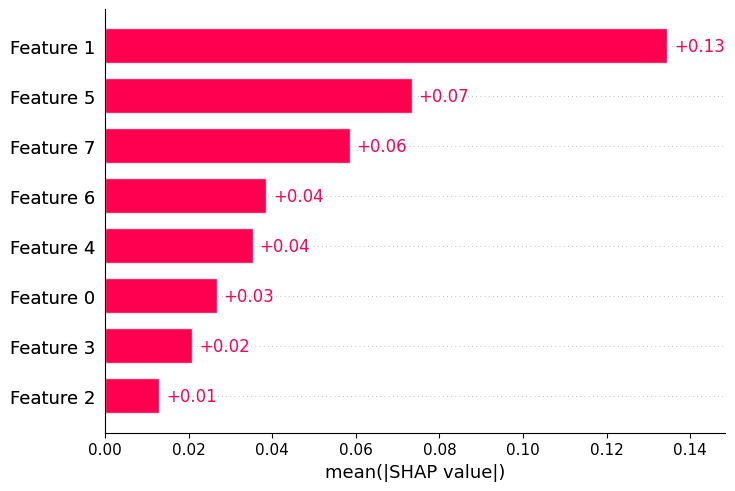

In [5]:
import shap
import pandas as pd, numpy as np, joblib
from sklearn.model_selection import train_test_split

url = "https://raw.githubusercontent.com/jbrownlee/Datasets/master/pima-indians-diabetes.data.csv"
cols = ["Pregnancies","Glucose","BloodPressure","SkinThickness",
        "Insulin","BMI","DiabetesPedigreeFunction","Age","Outcome"]
df = pd.read_csv(url, names=cols)
df[["Glucose","BloodPressure","SkinThickness","Insulin","BMI"]] = \
    df[["Glucose","BloodPressure","SkinThickness","Insulin","BMI"]].replace(0, np.nan)
X, y = df.drop(columns="Outcome"), df["Outcome"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2,
                                                     stratify=y, random_state=42)

rf = joblib.load("healthsignal_rf.pkl")
explainer = shap.TreeExplainer(rf.named_steps["clf"])
X_test_imp = rf.named_steps["imputer"].transform(X_test)

# handle all shap return formats
sv = explainer.shap_values(X_test_imp)
if isinstance(sv, list):
    sv = sv[1]
elif sv.ndim == 3:
    sv = sv[:, :, 1]

print("SHAP array shape:", sv.shape)  # should be (154, 8)

imp = pd.Series(np.abs(sv).mean(axis=0), index=X.columns).sort_values(ascending=False)
print("\n=== Mean |SHAP| per feature ===")
print(imp.round(4))

# also try shap's newer API (used by recent versions)
try:
    expl = explainer(X_test_imp)
    if hasattr(expl, "values") and expl.values.ndim == 3:
        expl = expl[:, :, 1]
    shap.plots.bar(expl, show=True)
except Exception as e:
    print("new API bar failed, using summary_plot:", e)
    shap.summary_plot(sv, X_test_imp, feature_names=X.columns, show=True)

In [8]:
import os, joblib
print(os.getcwd())              # should be /content
print(os.listdir("."))          # healthsignal_rf.pkl should be in the list

/content
['.config', 'healthsignal_rf.pkl', '.gradio', 'sample_data']


In [ ]:
import gradio as gr
import joblib
import numpy as np
import pandas as pd
import shap
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt

# ---------- load model & explainer ----------
MODEL = joblib.load("healthsignal_rf.pkl")
EXPLAINER = shap.TreeExplainer(MODEL.named_steps["clf"])
FEATURES = ["Pregnancies","Glucose","BloodPressure","SkinThickness",
            "Insulin","BMI","DiabetesPedigreeFunction","Age"]
THRESHOLD = 0.30   # chosen from evaluation sweep — see REPORT.md

# ---------- core prediction ----------
def predict(pregnancies, glucose, blood_pressure, skin_thickness,
            insulin, bmi, pedigree, age):
    # input validation
    if glucose < 40 or glucose > 400:
        return "⚠️ Glucose must be between 40–400 mg/dL.", None, ""
    if bmi < 10 or bmi > 70:
        return "⚠️ BMI must be between 10–70.", None, ""
    if age < 1 or age > 120:
        return "⚠️ Age must be between 1–120.", None, ""
    if blood_pressure < 30 or blood_pressure > 200:
        return "⚠️ Blood pressure must be between 30–200 mmHg.", None, ""
    if pregnancies < 0 or pregnancies > 20:
        return "⚠️ Pregnancies must be between 0–20.", None, ""

    # zeros on these features = missing → imputer handles them
    row = pd.DataFrame([{
        "Pregnancies": pregnancies,
        "Glucose": glucose if glucose > 0 else np.nan,
        "BloodPressure": blood_pressure if blood_pressure > 0 else np.nan,
        "SkinThickness": skin_thickness if skin_thickness > 0 else np.nan,
        "Insulin": insulin if insulin > 0 else np.nan,
        "BMI": bmi if bmi > 0 else np.nan,
        "DiabetesPedigreeFunction": pedigree,
        "Age": age,
    }])[FEATURES]

    proba = MODEL.predict_proba(row)[0, 1]
    flagged = proba >= THRESHOLD

    if proba < 0.20:
        band, color = "LOW estimated risk", "#16a34a"
    elif proba < THRESHOLD:
        band, color = "MODERATE estimated risk", "#d97706"
    else:
        band, color = "ELEVATED estimated risk — recommend professional assessment", "#dc2626"

    result_md = f"""
<div style="padding:18px;border-radius:12px;background:#f8fafc;
            border-left:6px solid {color};">
  <div style="font-size:13px;color:#64748b;text-transform:uppercase;
              letter-spacing:1px;">Estimated risk</div>
  <div style="font-size:28px;font-weight:600;color:{color};
              margin:6px 0;">{proba*100:.1f}%</div>
  <div style="font-size:15px;color:#0f172a;">{band}</div>
  <div style="font-size:12px;color:#334155;margin-top:10px;">
    Decision threshold: {THRESHOLD:.2f}. Screening flag:
    <b>{'YES' if flagged else 'NO'}</b>.
  </div>
</div>
"""

    # per-patient SHAP
    row_imp = MODEL.named_steps["imputer"].transform(row)
    sv = EXPLAINER.shap_values(row_imp)
    if isinstance(sv, list):
        sv = sv[1]
    elif sv.ndim == 3:
        sv = sv[:, :, 1]
    sv = sv[0]

    fig, ax = plt.subplots(figsize=(7, 3.2))
    order = np.argsort(np.abs(sv))
    colors = ["#dc2626" if v > 0 else "#2563eb" for v in sv[order]]
    ax.barh(np.array(FEATURES)[order], sv[order], color=colors)
    ax.axvline(0, color="#94a3b8", linewidth=0.8)
    ax.set_xlabel("Contribution to risk (SHAP value)")
    ax.set_title("Why this estimate? (red = raises risk, blue = lowers)",
                 fontsize=10, loc="left")
    ax.spines[["top","right"]].set_visible(False)
    plt.tight_layout()

    top = pd.Series(np.abs(sv), index=FEATURES).sort_values(ascending=False)
    top3 = top.head(3)
    explain_lines = [
        f"**{feat}** — measured **{row.iloc[0][feat] if not pd.isna(row.iloc[0][feat]) else 'not provided'}**"
        + (" (raises risk)" if sv[FEATURES.index(feat)] > 0 else " (lowers risk)")
        for feat in top3.index
    ]
    explanation_md = "### Top contributing factors\n\n" + "\n".join(f"- {l}" for l in explain_lines)

    return result_md, fig, explanation_md


# ---------- UI ----------
with gr.Blocks(title="HealthSignal AI") as demo:
    gr.Markdown("""
    # HealthSignal AI
    ### Intelligent Insights for Earlier Health Awareness

    Community health workers: enter routine measurements to estimate diabetes risk
    and identify individuals who may benefit from professional assessment.

    > ⚠️ **This project is a prototype and is not medical advice.**
    > It does not diagnose diabetes and does not replace a clinician.
    """)

    with gr.Row():
        with gr.Column(scale=1):
            gr.Markdown("### Health measurements")
            pregnancies = gr.Number(label="Pregnancies", value=2, precision=0)
            glucose     = gr.Number(label="Glucose (mg/dL)", value=120)
            bp          = gr.Number(label="Blood Pressure (mmHg)", value=70)
            skin        = gr.Number(label="Skin Thickness (mm, 0 = unknown)", value=0)
            insulin     = gr.Number(label="Insulin (μU/mL, 0 = unknown)", value=0)
            bmi         = gr.Number(label="BMI", value=28.5)
            pedigree    = gr.Number(label="Diabetes Pedigree Function", value=0.5)
            age         = gr.Number(label="Age (years)", value=35)
            btn = gr.Button("Estimate risk", variant="primary", size="lg")

        with gr.Column(scale=2):
            out_result = gr.HTML()
            out_expl   = gr.Markdown()
            out_plot   = gr.Plot()

    btn.click(predict,
              inputs=[pregnancies, glucose, bp, skin, insulin, bmi, pedigree, age],
              outputs=[out_result, out_plot, out_expl])

    with gr.Accordion("About this model & its limitations", open=False):
        gr.Markdown("""
        **Model:** Random Forest (300 trees), trained on the Pima Indians Diabetes dataset (768 samples).
        **Features:** Pregnancies, Glucose, Blood Pressure, Skin Thickness, Insulin, BMI, Diabetes Pedigree Function, Age.
        **Decision threshold:** 0.30 — chosen to prioritize recall (fewer missed cases) over precision, appropriate for a screening tool.

        **Limitations you must know:**
        - Trained on **women of Pima Indigenous descent** aged ≥21. Not validated for males, children, or other ethnic groups.
        - Data collected in the **1990s**; diagnostic criteria may have shifted.
        - **Insulin and Skin Thickness are ~30–49% missing** in the source data — treat those contributions with caution.
        - On the held-out test set the model missed **12 of 54 positive cases** (≈22% false negative rate). It is a screening aid, not a diagnosis.
        - Performance differences across demographic subgroups were **not** evaluated — the dataset lacks that granularity.

        **This project is a prototype and is not medical advice.**
        """)

demo.launch(theme=gr.themes.Soft(), share=True, debug=False)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://1a80f5600172e90a7f.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
